# EDA – SMS Spam Collection (Đề 3, Thành viên 1)

Notebook đọc dữ liệu, kiểm tra chất lượng, làm sạch, phân tích nhãn, thống kê trùng lặp và độ dài tin nhắn. Chạy lần lượt các ô hoặc chọn **Run All**.

In [1]:
import csv
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))
from src.data_loader import load_dataset

DATA_PATH = ROOT_DIR / "data" / "SMSSpamCollection"
FIGURE_DIR = ROOT_DIR / "report" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Đọc dữ liệu và xem tổng quan

In [2]:
raw_records = []
malformed_record_count = 0
with DATA_PATH.open(encoding="utf-8", newline="") as dataset_file:
    for row in csv.reader(dataset_file, delimiter="\t"):
        if len(row) != 2:
            malformed_record_count += 1
            continue
        raw_records.append(row)
raw_df = pd.DataFrame(raw_records, columns=["label", "text"], dtype="string")
df = load_dataset(DATA_PATH)
physical_line_count = sum(1 for _ in DATA_PATH.open(encoding="utf-8"))
print("Số dòng vật lý trong file:", physical_line_count)
print("Số bản ghi sai định dạng TSV:", malformed_record_count)
print("Kích thước dữ liệu gốc (bản ghi TSV):", raw_df.shape)
print("Schema sau xử lý:", df.columns.tolist())
display(df.head(10))
df.info()

Số bản ghi ban đầu: 5572
Số bản ghi sai định dạng TSV: 0
Bản ghi thiếu nhãn: 0
Bản ghi thiếu nội dung: 0
Bản ghi thiếu nhãn hoặc nội dung: 0
Số bản ghi có nhãn không hợp lệ: 0
Số bản ghi trùng hoàn toàn đã loại: 403
Số nội dung có nhãn xung đột: 0; số bản ghi liên quan (được giữ lại): 0
Số bản ghi sau xử lý: 5169
Các cột: ['label', 'text']
Phân bố nhãn:
 label
ham     4516
spam     653
Name: count, dtype: Int64
Số dòng vật lý trong file: 5574
Số bản ghi sai định dạng TSV: 0
Kích thước dữ liệu gốc (bản ghi TSV): (5572, 2)
Schema sau xử lý: ['label', 'text']


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


<class 'pandas.DataFrame'>
RangeIndex: 5169 entries, 0 to 5168
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5169 non-null   string
 1   text    5169 non-null   string
dtypes: string(2)
memory usage: 80.9 KB


## 2. Kiểm tra dữ liệu thiếu, trùng và nhãn

In [3]:
missing_label_mask = raw_df["label"].isna() | raw_df["label"].str.strip().eq("")
missing_text_mask = raw_df["text"].isna() | raw_df["text"].str.strip().eq("")
missing_record_mask = missing_label_mask | missing_text_mask
missing_label_count = int(missing_label_mask.sum())
missing_text_count = int(missing_text_mask.sum())
missing_record_count = int(missing_record_mask.sum())
print("Bản ghi thiếu nhãn:", missing_label_count)
print("Bản ghi thiếu nội dung:", missing_text_count)
print("Bản ghi thiếu nhãn hoặc nội dung:", missing_record_count)
print("Phân bố nhãn gốc:")
display(raw_df["label"].value_counts(dropna=False))

eligible_df = raw_df.loc[~missing_record_mask].copy()
eligible_df["label"] = eligible_df["label"].str.strip().str.lower()
eligible_df = eligible_df[eligible_df["label"].isin(["ham", "spam"])]
invalid_label_count = int((~raw_df.loc[~missing_record_mask, "label"].str.strip().str.lower().isin(["ham", "spam"])).sum())
duplicate_count = int(eligible_df.duplicated(["label", "text"]).sum())
unique_df = eligible_df.drop_duplicates(["label", "text"], keep="first")
labels_per_text = unique_df.groupby("text")["label"].nunique()
conflicting_texts = labels_per_text[labels_per_text > 1].index
conflicting_text_count = len(conflicting_texts)
conflicting_record_count = int(unique_df["text"].isin(conflicting_texts).sum())
print("Bản ghi đủ điều kiện trước khi loại trùng:", len(eligible_df))
print("Bản ghi nhãn không hợp lệ:", invalid_label_count)
print("Bản ghi trùng hoàn toàn sẽ loại:", duplicate_count)
print("Nội dung có nhãn xung đột (được giữ):", conflicting_text_count)
print("Bản ghi thuộc nội dung xung đột (được giữ):", conflicting_record_count)

Bản ghi thiếu nhãn: 0
Bản ghi thiếu nội dung: 0
Bản ghi thiếu nhãn hoặc nội dung: 0
Phân bố nhãn gốc:


label
ham     4825
spam     747
Name: count, dtype: Int64

Bản ghi đủ điều kiện trước khi loại trùng: 5572
Bản ghi nhãn không hợp lệ: 0
Bản ghi trùng hoàn toàn sẽ loại: 403
Nội dung có nhãn xung đột (được giữ): 0
Bản ghi thuộc nội dung xung đột (được giữ): 0


## 3. Làm sạch dữ liệu

In [4]:
print("Số bản ghi ban đầu:", len(raw_df))
print("Số bản ghi thiếu nhãn:", missing_label_count)
print("Số bản ghi thiếu nội dung:", missing_text_count)
print("Số bản ghi thiếu nhãn hoặc nội dung:", missing_record_count)
print("Số bản ghi có nhãn không hợp lệ:", invalid_label_count)
print("Số bản ghi hợp lệ trước khi loại trùng:", len(eligible_df))
print("Số bản ghi sau xử lý:", len(df))
print("Số bản ghi trùng đã loại:", duplicate_count)
print("Số nội dung có nhãn xung đột:", conflicting_text_count)
print("Số bản ghi thuộc nội dung xung đột:", conflicting_record_count)
display(df.head())
display(df.isna().sum().to_frame("missing_after_cleaning"))
assert df.columns.tolist() == ["label", "text"]
assert df["label"].isin(["ham", "spam"]).all()
assert not df.isna().any().any()
assert not df.duplicated(["label", "text"]).any()

Số bản ghi ban đầu: 5572
Số bản ghi thiếu nhãn: 0
Số bản ghi thiếu nội dung: 0
Số bản ghi thiếu nhãn hoặc nội dung: 0
Số bản ghi có nhãn không hợp lệ: 0
Số bản ghi hợp lệ trước khi loại trùng: 5572
Số bản ghi sau xử lý: 5169
Số bản ghi trùng đã loại: 403
Số nội dung có nhãn xung đột: 0
Số bản ghi thuộc nội dung xung đột: 0


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,missing_after_cleaning
label,0
text,0


## 4. Phân bố nhãn ham/spam

,count,percentage
label,,
ham,4516,87.37
spam,653,12.63


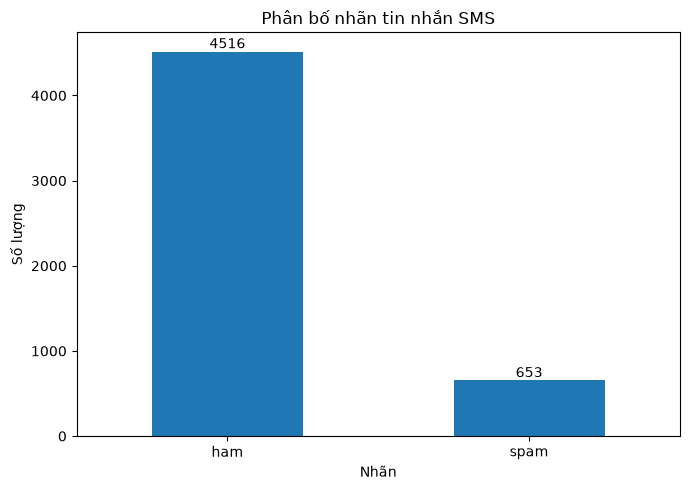

In [5]:
label_counts = df["label"].value_counts().reindex(["ham", "spam"], fill_value=0)
label_percent = (label_counts / len(df) * 100).round(2)
display(pd.DataFrame({"count":label_counts, "percentage":label_percent}))
ax = label_counts.plot(kind="bar", rot=0, figsize=(7,5))
ax.set(title="Phân bố nhãn tin nhắn SMS", xlabel="Nhãn", ylabel="Số lượng")
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout()
plt.savefig(FIGURE_DIR/"label_distribution.png", dpi=180)
plt.show()

## 5. Tin nhắn trùng lặp và độ dài

,count,mean,median,min,max
label,,,,,
ham,4516,70.91,53.0,2,910
spam,653,137.7,148.0,13,223


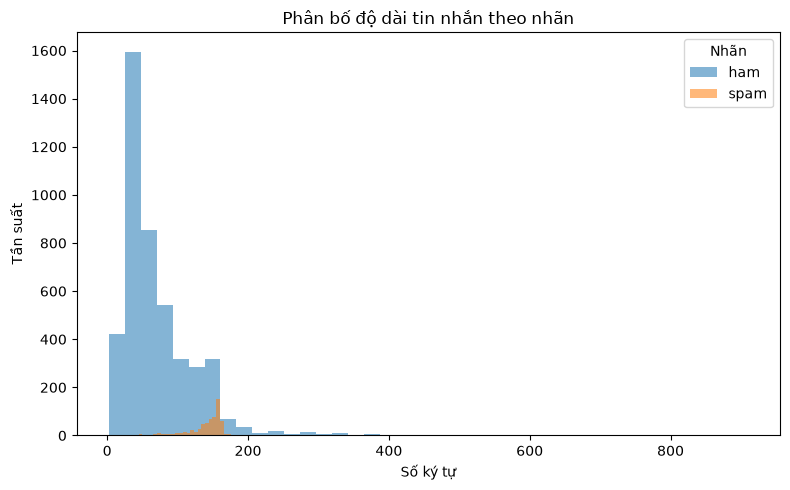

In [6]:
df["message_length"] = df["text"].str.len()
display(df.groupby("label")["message_length"].agg(["count", "mean", "median", "min", "max"]).round(2))
plt.figure(figsize=(8,5))
for lab in ["ham","spam"]:
    plt.hist(df.loc[df.label == lab, "message_length"], bins=40, alpha=.55, label=lab)
plt.title("Phân bố độ dài tin nhắn theo nhãn")
plt.xlabel("Số ký tự"); plt.ylabel("Tần suất"); plt.legend(title="Nhãn")
plt.tight_layout()
plt.savefig(FIGURE_DIR/"message_length.png", dpi=180)
plt.show()

## 6. Kết luận EDA

In [7]:
total = len(df)
for lab in ["ham","spam"]:
    n = int((df.label == lab).sum())
    print(f"{lab}: {n:,} tin nhắn ({n/total:.2%})")
print("\nĐộ dài trung bình theo nhãn:")
display(df.groupby("label")["message_length"].mean().round(2))

ham: 4,516 tin nhắn (87.37%)
spam: 653 tin nhắn (12.63%)

Độ dài trung bình theo nhãn:


label
ham     70.91
spam    137.7
Name: message_length, dtype: Float64